In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "00_E0.3_phan_bo_va_quan_he_muc_phut_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:00:52 | INFO | Bắt đầu chạy 00_E0.3_phan_bo_va_quan_he_muc_phut_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0000_00_E0.3_phan_bo_va_quan_he_muc_phut_Han.log


# E0.3 – Phân bố và quan hệ giữa các cột ở mức phút

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.3 – Phân bố và quan hệ giữa các cột ở mức phút |
| **Mục đích** | Phân bố 7 biến đo, đơn vị, quan hệ vật lý giữa công suất, dòng điện, công tơ phụ, và độ nhiễu mức phút so với mức giờ. |
| **Đọc vào** | `data/raw/individual+household+electric+power+consumption.zip` (đọc thẳng từ zip) |
| **Ghi ra** | `data/eda_data/eda_00_thong_ke_phut.csv`, `figures/eda_figures/00_phan_bo_7_bien_phut.png`, `figures/eda_figures/00_cong_suat_va_dong_dien.png`, `figures/eda_figures/00_mot_ngay_phut_va_gio.png`, `data/eda_data/eda_E0.3_kho_khan.csv` |
| **Chạy sau** | không cần |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ZIP = ROOT / "data" / "raw" / "individual+household+electric+power+consumption.zip"
TXT = "household_power_consumption.txt"
DIR_DATA, DIR_FIG = ROOT / "data" / "eda_data", ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(exist_ok=True)

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
DON_VI = {"Global_active_power": "kW", "Global_reactive_power": "kVAR", "Voltage": "V",
          "Global_intensity": "A", "Sub_metering_1": "Wh/phút", "Sub_metering_2": "Wh/phút",
          "Sub_metering_3": "Wh/phút"}
SEED = 42

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def runs(mask):
    """Các đoạn True liên tiếp: trả về (vị trí bắt đầu, độ dài)."""
    m = np.concatenate(([0], np.asarray(mask).astype(np.int8), [0]))
    d = np.diff(m)
    return np.where(d == 1)[0], np.where(d == -1)[0] - np.where(d == 1)[0]

kho_khan = []   # bảng "khó khăn dữ liệu → cách xử lý", điền dần qua từng mục
def ghi_kho_khan(kho_khan_, bang_chung, cach_xu_ly, o_dau):
    kho_khan.append({"Khó khăn": kho_khan_, "Bằng chứng (số thật)": bang_chung,
                     "Cách xử lý": cach_xu_ly, "Xử lý ở đâu": o_dau})

log.info(f"ROOT: {ROOT}")
log.info(f"File dữ liệu: {ZIP.name} ({ZIP.stat().st_size / 1024**2:.2f} MB)")

2026-11-14 00:00:52 | INFO | ROOT: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy


2026-11-14 00:00:52 | INFO | File dữ liệu: individual+household+electric+power+consumption.zip (19.68 MB)


In [3]:
# [CHUẨN BỊ RIÊNG] Đọc lại dữ liệu thô và trục thời gian (giống E0.1) để notebook này chạy độc lập
with zipfile.ZipFile(ZIP) as z:
    raw_str = pd.read_csv(z.open(TXT), sep=";", dtype=str, keep_default_na=False)
n_dong, n_cot = raw_str.shape
thieu = raw_str[COLS].isin(["?", ""])
ts = pd.to_datetime(raw_str["Date"] + " " + raw_str["Time"], format="%d/%m/%Y %H:%M:%S")
log.info(f"Đã đọc {fmt(n_dong)} dòng, từ {ts.iloc[0]:%d/%m/%Y %H:%M} đến {ts.iloc[-1]:%d/%m/%Y %H:%M}")

2026-11-14 00:00:56 | INFO | Đã đọc 2.075.259 dòng, từ 16/12/2006 17:24 đến 26/11/2010 21:02


In [4]:
MA_TN = "E0.3"
moc_kk = len(kho_khan)   # các khó khăn ghi từ đây trở đi thuộc E0.3

## 5. Phân bố của 7 biến ở mức phút
Thống kê mô tả, độ lệch và tỉ lệ giá trị 0. Hình vẽ trên mẫu ngẫu nhiên 200.000 phút (seed 42) cho nhanh; các con số trong bảng tính trên toàn bộ dữ liệu.

,count,mean,std,min,25%,50%,75%,max,skew,ti_le_bang_0_%,don_vi
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,0.0,kW
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,23.5,kVAR
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.0,V
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,0.0,A
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,91.7,Wh/phút
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,70.1,Wh/phút
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,41.6,Wh/phút


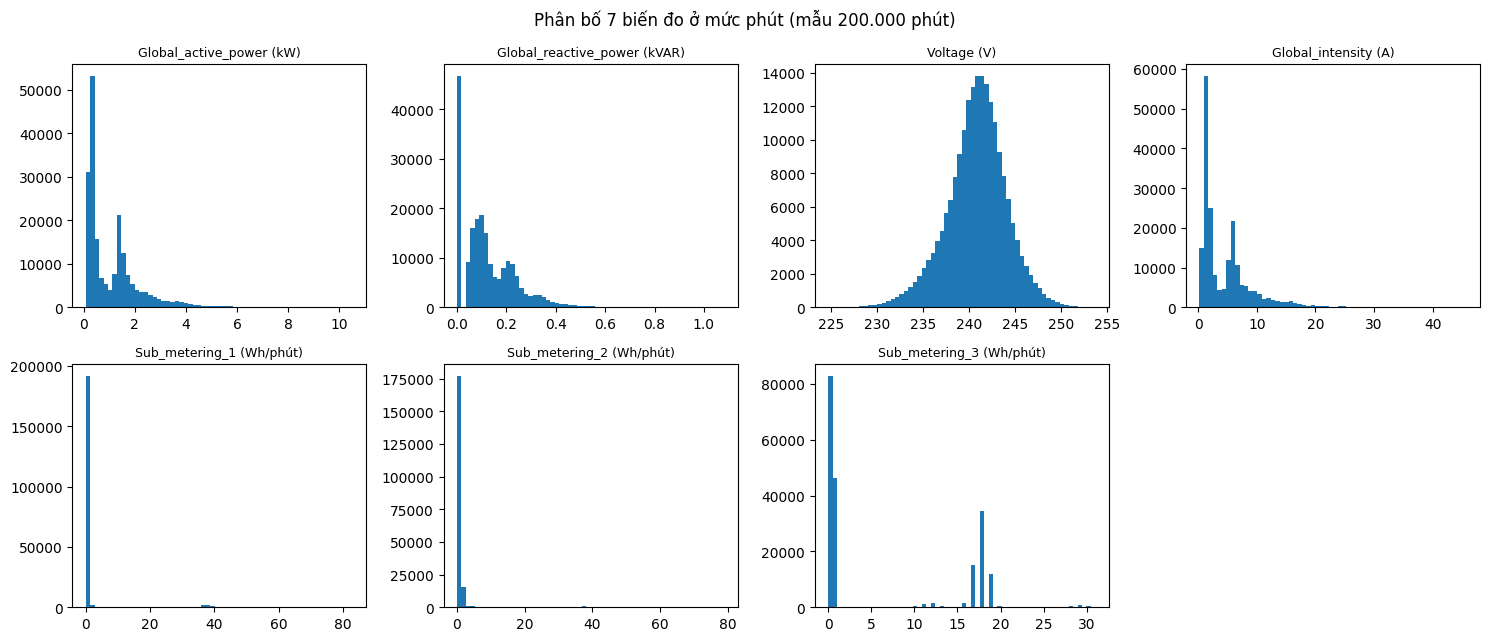

2026-11-14 00:00:59 | INFO | Độ lệch Global_active_power mức phút: 1.79


2026-11-14 00:00:59 | INFO | Tỉ lệ giá trị bằng 0: Sub_metering_1 91.7%; Sub_metering_2 70.1%; Sub_metering_3 41.6%


In [5]:
df = raw_str[COLS].replace({"?": np.nan, "": np.nan}).astype(float)
df.index = ts
del raw_str

tk = df.describe().T
tk["skew"] = df.skew()
tk["ti_le_bang_0_%"] = ((df == 0).sum() / df.notna().sum() * 100).round(1)
tk["don_vi"] = pd.Series(DON_VI)
tk.round(3).to_csv(DIR_DATA / "eda_00_thong_ke_phut.csv", encoding="utf-8-sig")
display(tk.round(3))

mau = df.dropna().sample(200_000, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, COLS):
    ax.hist(mau[c], bins=60)
    ax.set_title(f"{c} ({DON_VI[c]})", fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Phân bố 7 biến đo ở mức phút (mẫu 200.000 phút)")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_phan_bo_7_bien_phut.png", dpi=150); plt.show()

log.info(f"Độ lệch {TARGET} mức phút: {tk.loc[TARGET, 'skew']:.2f}")
log.info("Tỉ lệ giá trị bằng 0: " + "; ".join(f"{c} {tk.loc[c, 'ti_le_bang_0_%']}%" for c in SUB_COLS))
ghi_kho_khan("Phân bố lệch phải, công tơ phụ phần lớn bằng 0",
             f"{TARGET} skew = {tk.loc[TARGET, 'skew']:.2f}; Sub_metering_1 bằng 0 ở {tk.loc['Sub_metering_1', 'ti_le_bang_0_%']}% số phút, "
             f"Sub_metering_2 {tk.loc['Sub_metering_2', 'ti_le_bang_0_%']}%",
             "Ngoại lệ theo IQR chỉ đánh dấu, không xoá (đỉnh tiêu thụ là hành vi thật); với công tơ phụ IQR không dùng được vì đa số bằng 0",
             "01_cleaning, mục 6")
ghi_kho_khan("Các cột khác đơn vị và khác thang đo",
             "kW, kVAR, V, A, Wh/phút; Voltage quanh " + f"{tk.loc['Voltage', 'mean']:.0f} V trong khi công suất quanh {tk.loc[TARGET, 'mean']:.2f} kW",
             "Khi gộp theo giờ: lấy trung bình cho 4 biến điện, lấy tổng cho 3 công tơ phụ (Wh); Linear Regression dùng StandardScaler",
             "01_cleaning, mục 7; pipeline mô hình")

**Nhận xét:** 

Global_active_power có trung bình 1,092 kW nhưng trung vị chỉ 0,602 kW, độ lệch 1,79, nghĩa là phần lớn thời gian nhà dùng ít điện và chỉ thỉnh thoảng có lúc dùng rất nhiều. Ba công tơ phụ bằng 0 rất nhiều (91,7%, 70,1%, 41,6%) vì các thiết bị đó chỉ chạy lúc có người dùng. Các cột có đơn vị khác nhau (kW, V, A, Wh/phút) nên phải đổi về cùng đơn vị nếu muốn so sánh.


## 6. Các cột liên hệ với nhau thế nào?
- **Công suất và dòng điện:** về mặt vật lý, công suất ≈ điện áp × dòng điện × hệ số công suất. Nếu đúng vậy thì `Global_intensity` gần như là một bản sao của biến mục tiêu.
- **Điện năng cả hộ và công tơ phụ:** điện năng mỗi phút của cả hộ là `Global_active_power × 1000 / 60` (Wh). Phần còn lại sau khi trừ 3 công tơ phụ là điện năng của các thiết bị không có công tơ riêng; phần này không thể âm.

2026-11-14 00:00:59 | INFO | Tương quan Global_active_power – Global_intensity (mức phút): r = 0.9989


2026-11-14 00:00:59 | INFO | P / (V × I): trung vị 0.992; 5.75% số phút lớn hơn 1,05


2026-11-14 00:00:59 | INFO | Phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: 1.050 (0.051%), âm nhiều nhất -2.4 Wh


2026-11-14 00:00:59 | INFO | Tỉ trọng điện năng: Sub_metering_1 6.2%; Sub_metering_2 7.1%; Sub_metering_3 35.5%; còn lại 51.2%


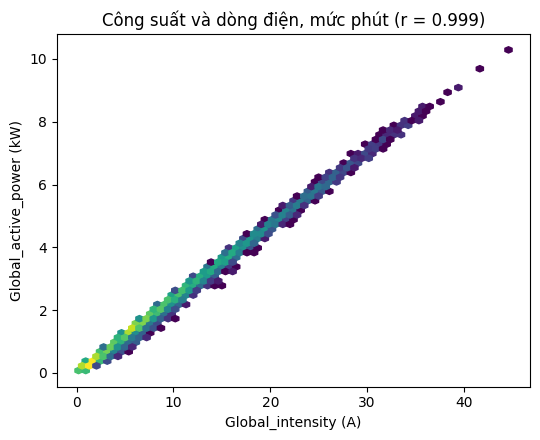

In [6]:
d = df.dropna()
r_I = d[TARGET].corr(d["Global_intensity"])
he_so = d[TARGET] * 1000 / (d["Voltage"] * d["Global_intensity"])
log.info(f"Tương quan {TARGET} – Global_intensity (mức phút): r = {r_I:.4f}")
log.info(f"P / (V × I): trung vị {he_so.median():.3f}; {(he_so > 1.05).mean():.2%} số phút lớn hơn 1,05")

dien_nang = d[TARGET] * 1000 / 60
con_lai = dien_nang - d[SUB_COLS].sum(axis=1)
am = int((con_lai < 0).sum())
ti_trong = (d[SUB_COLS].sum() / dien_nang.sum() * 100).round(1)
log.info(f"Phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: {fmt(am)} ({am / len(d):.3%}), âm nhiều nhất {con_lai.min():.1f} Wh")
log.info("Tỉ trọng điện năng: " + "; ".join(f"{c} {v}%" for c, v in ti_trong.items()) + f"; còn lại {100 - ti_trong.sum():.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
m = d.sample(100_000, random_state=SEED)
ax.hexbin(m["Global_intensity"], m[TARGET], gridsize=60, bins="log", mincnt=1)
ax.set_xlabel("Global_intensity (A)"); ax.set_ylabel("Global_active_power (kW)")
ax.set_title(f"Công suất và dòng điện, mức phút (r = {r_I:.3f})")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_cong_suat_va_dong_dien.png", dpi=150); plt.show()

ghi_kho_khan("Global_intensity gần như trùng với biến mục tiêu",
             f"r = {r_I:.3f} ở mức phút, vì công suất ≈ điện áp × dòng điện",
             "Không dùng Global_intensity của cùng giờ cần dự báo; chỉ dùng giá trị của các giờ trước (trễ) làm đặc trưng",
             "03_features")
ghi_kho_khan("Tổng công tơ phụ đôi khi lớn hơn điện năng cả hộ",
             f"{fmt(am)} phút ({am / len(d):.3%}), lệch nhiều nhất {abs(con_lai.min()):.1f} Wh",
             "Chỉ ghi nhận, không sửa (sai số làm tròn và sai số đo của công tơ)",
             "01_cleaning, mục 5")

**Nhận xét:** 

Công suất và dòng điện tương quan gần như tuyệt đối (r = 0,9989), vì công suất ≈ điện áp × dòng điện. Do đó không nên dùng Global_intensity của cùng thời điểm để dự báo công suất, vì như vậy là biết trước đáp án. Ba công tơ phụ chỉ đo được một phần điện năng (6,2%, 7,1% và 35,5%), 51,2% còn lại là các thiết bị không có công tơ riêng.

## 7. Mức phút hay mức giờ?
So sánh một ngày đủ dữ liệu ở mức phút với trung bình theo giờ của cùng ngày.

2026-11-14 00:00:59 | INFO | Ngày minh hoạ 01/01/2008: độ lệch chuẩn mức phút 1.026 kW, mức giờ 0.803 kW


2026-11-14 00:00:59 | INFO | Thay đổi trung bình giữa 2 phút liên tiếp: 0.084 kW; 1.93% số lần đổi hơn 1 kW chỉ trong 1 phút


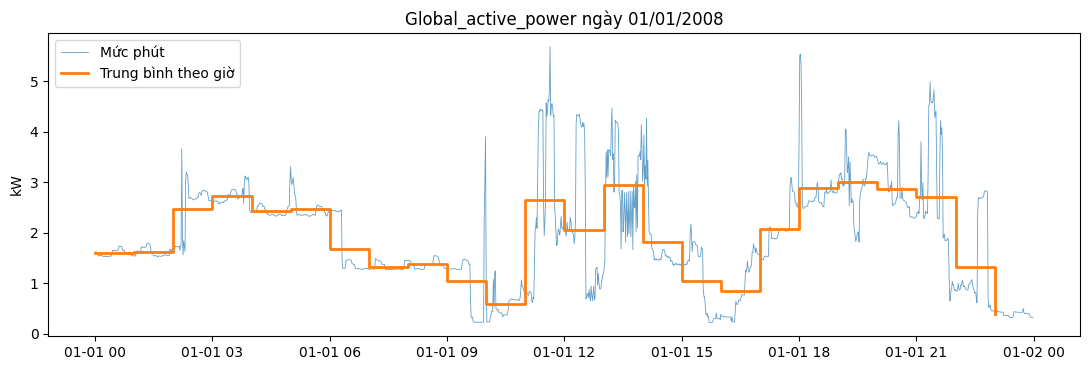

In [7]:
ngay_du = d[TARGET].resample("D").count()
ngay = ngay_du[ngay_du == 1440].index[ngay_du[ngay_du == 1440].index >= "2008-01-01"][0]
mot_ngay = df.loc[f"{ngay:%Y-%m-%d}", TARGET]
theo_gio = mot_ngay.resample("h").mean()
log.info(f"Ngày minh hoạ {ngay:%d/%m/%Y}: độ lệch chuẩn mức phút {mot_ngay.std():.3f} kW, mức giờ {theo_gio.std():.3f} kW")
bien_dong = df[TARGET].diff().abs()
log.info(f"Thay đổi trung bình giữa 2 phút liên tiếp: {bien_dong.mean():.3f} kW; "
         f"{(bien_dong > 1).mean():.2%} số lần đổi hơn 1 kW chỉ trong 1 phút")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(mot_ngay.index, mot_ngay.values, lw=0.6, alpha=0.7, label="Mức phút")
ax.step(theo_gio.index, theo_gio.values, where="post", lw=2, label="Trung bình theo giờ")
ax.set_ylabel("kW"); ax.set_title(f"Global_active_power ngày {ngay:%d/%m/%Y}"); ax.legend()
fig.tight_layout(); fig.savefig(DIR_FIG / "00_mot_ngay_phut_va_gio.png", dpi=150); plt.show()

ghi_kho_khan("Dữ liệu mức phút rất nhiễu",
             f"Trung bình mỗi phút công suất đổi {bien_dong.mean():.3f} kW; {(bien_dong > 1).mean():.2%} số lần đổi hơn 1 kW trong 1 phút",
             "Gộp thành trung bình theo giờ và dự báo giờ kế tiếp (giờ hợp lệ khi có ít nhất 30 phút đo được)",
             "01_cleaning, mục 7")

**Nhận xét:** 

Dữ liệu mức phút dao động mạnh: trong ngày 01/01/2008, độ lệch chuẩn mức phút là 1,026 kW, còn mức giờ là 0,803 kW, và có 1,93% số lần công suất thay đổi hơn 1 kW chỉ trong 1 phút. Gộp theo giờ giúp dữ liệu bớt nhiễu, đây là lý do nhóm chọn dự báo theo giờ.

## Khó khăn dữ liệu rút ra từ E0.3

In [8]:
bang_kk = pd.DataFrame(kho_khan[moc_kk:])
bang_kk.to_csv(DIR_DATA / f"eda_{MA_TN}_kho_khan.csv", encoding="utf-8-sig", index=False)
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)
log.info(f"{MA_TN}: {len(bang_kk)} khó khăn dữ liệu, lưu ở data/eda_data/eda_{MA_TN}_kho_khan.csv")

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
0,"Phân bố lệch phải, công tơ phụ phần lớn bằng 0","Global_active_power skew = 1.79; Sub_metering_1 bằng 0 ở 91.7% số phút, Sub_metering_2 70.1%","Ngoại lệ theo IQR chỉ đánh dấu, không xoá (đỉnh tiêu thụ là hành vi thật); với công tơ phụ IQR không dùng được vì đa số bằng 0","01_cleaning, mục 6"
1,Các cột khác đơn vị và khác thang đo,"kW, kVAR, V, A, Wh/phút; Voltage quanh 241 V trong khi công suất quanh 1.09 kW","Khi gộp theo giờ: lấy trung bình cho 4 biến điện, lấy tổng cho 3 công tơ phụ (Wh); Linear Regression dùng StandardScaler","01_cleaning, mục 7; pipeline mô hình"
2,Global_intensity gần như trùng với biến mục tiêu,"r = 0.999 ở mức phút, vì công suất ≈ điện áp × dòng điện",Không dùng Global_intensity của cùng giờ cần dự báo; chỉ dùng giá trị của các giờ trước (trễ) làm đặc trưng,03_features
3,Tổng công tơ phụ đôi khi lớn hơn điện năng cả hộ,"1.050 phút (0.051%), lệch nhiều nhất 2.4 Wh","Chỉ ghi nhận, không sửa (sai số làm tròn và sai số đo của công tơ)","01_cleaning, mục 5"
4,Dữ liệu mức phút rất nhiễu,Trung bình mỗi phút công suất đổi 0.084 kW; 1.93% số lần đổi hơn 1 kW trong 1 phút,Gộp thành trung bình theo giờ và dự báo giờ kế tiếp (giờ hợp lệ khi có ít nhất 30 phút đo được),"01_cleaning, mục 7"


2026-11-14 00:00:59 | INFO | E0.3: 5 khó khăn dữ liệu, lưu ở data/eda_E0.3_kho_khan.csv


## Log lên W&B (minh chứng)

In [9]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_00_thong_ke_phut.csv', 'eda_E0.3_kho_khan.csv']
    HINH = ['00_phan_bo_7_bien_phut.png', '00_cong_suat_va_dong_dien.png', '00_mot_ngay_phut_va_gio.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.3-Han-phan-bo-va-quan-he-muc-phut", tags=["E0.3", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({"skew_global_active_power_phut": float(tk.loc[TARGET, 'skew']), "r_cong_suat_dong_dien_phut": float(r_I), "so_phut_cong_to_phu_vuot": int(am)})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in kho_khan[moc_kk:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run byu69e9z


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000101-byu69e9z
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.3-Han-phan-bo-va-quan-he-muc-phut


... (8 outputs left out)

wandb: uploading artifact run-byu69e9z-bangeda_00_thong_ke_phut-kknFxw


wandb: 
wandb: Run summary:
wandb:    r_cong_suat_dong_dien_phut 0.99889
wandb: skew_global_active_power_phut 1.78623
wandb:      so_phut_cong_to_phu_vuot 1050
wandb: 


wandb: 🚀 View run ck-E0.3-Han-phan-bo-va-quan-he-muc-phut at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/byu69e9z
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 6 media file(s), 4 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000101-byu69e9z/logs


## Nhật ký

- 13/11/2026 – Viết lần đầu chung trong notebook `00_eda_du_lieu_tho_Han.ipynb` (nay ở `phien_ban_cu/`) rồi tách ra thành notebook riêng `00_E0.3_phan_bo_va_quan_he_muc_phut_Han.ipynb`, có ô ghi log. Commit `ac41623`.
- 13/11/2026 – Chạy 3 lần (19:36, 20:11, 20:15). Lần đầu chạy xong nhưng đóng tab chưa lưu nên notebook mất output; lần cuối chạy bằng `jupyter nbconvert` để lưu output. Nội dung 3 file log trùng nhau (chỉ khác giờ chạy), tức là kết quả tái lập được. Commit `84d20b1`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.